# profilePlots

In [2]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
def scanFile(data):
    types = ["positive", "negative", "both"]
    tiers = ["<= 25%", "<= 50%", "<= 75%", "<= 100%"]
    typeIndex = 0
    
    spotNames =[]
    rawData = []
    normalizedData = []
    positives = []
    negatives = []
    
    for sample in data["samples"]:
        if not hasLowVariance(sample["data"]):
            if sample["type"][0] == "positive":
                positives.append(sample)
            else:
                negatives.append(sample)
    
    #searchForEpitopesTree(positives, searchForEpitopesArea(positives))
    
    positives = splitSetsIntoTiers(4,(2 ** 16 -1),positives)
    negatives = splitSetsIntoTiers(4,(2 ** 16 -1),negatives)
    
    boxScatterPlot(positives[0] + positives[1] + positives[2] + positives[3], "pos")

In [4]:
def splitSetsIntoTiers(nTiers, maxValue, data):
    tData = []
    
    for i in range(nTiers):
        tData.append([])
        
    tierStep = maxValue / nTiers
    
    for counter, dataSet in enumerate(data):
        maxPoint = 0
        for dataPoint in dataSet["data"]:
            if float(dataPoint["rawIntensity"]) > maxPoint:
                maxPoint = float(dataPoint["rawIntensity"])
                
        for i in range(nTiers):
            if maxPoint <= tierStep * (i+1):
                tData[i].append(dataSet)
                break
                
    return tData

In [5]:
def hasLowVariance(dataSet):
    stringency = 0.25
    
    avg = 0
    maximum = 0
    count = 0
    for spot in dataSet:
        count +=1
        avg += float(spot["rawIntensity"])
        if float(spot["rawIntensity"]) > maximum:
            maximum = float(spot["rawIntensity"])
    
    avg /= count
    if avg / maximum <= stringency :
        return False
    
    return True

In [6]:
def indexToPosition (index):
    return ""+chr(int(index/24)+65) + str(index%24 + 1)

In [7]:
def positionToIndex (position):
    letter = (ord(position[0]) - 65)*24
    number = int(position[1:]) -1
    
    return letter + number

In [8]:
def boxScatterPlot(dataSet, title):
    nameSet = []
    boxSetsRaw = []
    boxSetsAbsNorm = []
    boxSetsNorm = []
    boxSetsThresholdedAbsNorm = []
    thresholds = [1.1, 0.9980313183356757, 0.3020478190965463, 0.17250974732552216]
    for threshold in thresholds:
        for dSet in dataSet: 
            if dSet["name"] == "SC77":
                nameSet.append(dSet["name"] + " - "+ str(threshold))
                boxSetRaw = []
                boxSetAbsNorm = []
                boxSetNorm = []
                boxSetThresholdedAbsNorm = []


                for spot in dSet["data"]:
                    boxSetRaw.append(float(spot["rawIntensity"]))
                    boxSetAbsNorm.append(float(spot["rawIntensity"])/(2**16 -1))
                    
                    if(float(spot["normalizedIntensity"]) < threshold):
                        boxSetNorm.append(float(spot["normalizedIntensity"]))

                    if(float(spot["normalizedIntensity"]) < threshold):
                        boxSetThresholdedAbsNorm.append(float(spot["rawIntensity"])/(2**16 -1))

                boxSetsRaw.append(boxSetRaw)
                boxSetsAbsNorm.append(boxSetAbsNorm)
                boxSetsNorm.append(boxSetNorm)
                boxSetsThresholdedAbsNorm.append(boxSetThresholdedAbsNorm)
        
    
    plotSet = boxSetAbsNorm
    #plt.title(title)
    fig = plt.figure(figsize =(30,10))#130))
    sns.set(font_scale = 2)
    #plt.axvline(x = 0.6,linewidth=4, color='r')
    plt.axvline(x = 0.25,linewidth=4, color='r')
    plt.axvline(x = 0.5,linewidth=4, color='r')
    plt.axvline(x = 0.75,linewidth=4, color='r')

    ax = sns.boxplot(data = plotSet, orient = "h")
    #ax = sns.swarmplot(data = plotSet, orient = "h", s=10, linewidth = 2)
    print(nameSet)
    #ax.set_yticklabels(nameSet)
    plt.show()
    fig.savefig("C:/Users/KaiKr/Desktop/boxScatterPlot.png", dpi=50)

In [9]:
def getDeltaSet(data):
    types = ["positive", "negative", "both"]
    tiers = ["<= 25%", "<= 50%", "<= 75%", "<= 100%"]
    typeIndex = 0
    
    positives = []
    negatives = []
    
    for sample in data["samples"]:
        if not hasLowVariance(sample["data"]):
            if sample["type"][0] == "positive":
                positives.append(sample)
            else:
                negatives.append(sample)
    
    nValues = []
    setNames = []
    for sample in positives:
        nVal = []
        setNames.append(sample["name"])
        for spot in sample["data"]:
            nVal.append(float(spot["normalizedIntensity"]))
        #nVal.sort()
        nValues.append(nVal)
    
    deltaValues = []
    for sample in nValues:
        dValues = []
        for counter, spot in enumerate(sample):
            if counter < (len(sample) -1):
                dValues.append(sample[counter +1] - spot)
        deltaValues.append(dValues.copy())
    
    filteredDeltaValues = []
    for counter, dValues in enumerate(deltaValues):
        q1 = np.quantile(dValues, 0.25)
        q3 = np.quantile(dValues, 0.75)
        iqr = q3-q1
        upperBound = q3+(1.5*iqr)
        lowerBound = q1-(1.5*iqr)
        dVal = []
        for value in dValues:
            if value > upperBound:
                dVal.append(value)
        filteredDeltaValues.append(dVal.copy())
    
    fig = plt.figure(figsize =(50,130))
    sns.set(font_scale = 2)
    
    #ax = sns.barplot(x = nValues[0], y = name)
#     ax = sns.boxplot(data = filteredDeltaValues, orient = "h")
#     ax = sns.swarmplot(data = filteredDeltaValues, orient = "h", s=10, linewidth = 2)
    #ax.set_yticklabels(setNames)
    plt.show()
                        
    #positives = splitSetsIntoTiers(4,(2 ** 16 -1),positives)
    #negatives = splitSetsIntoTiers(4,(2 ** 16 -1),negatives)

In [10]:
def getDeltaBarchart(data):
    spots = []
    sampleName = "M092"
    for sample in data["samples"]:
        if sample["name"] == sampleName:
            sampleData = sample
            break
    
    spotNames = []
    for counter, spot in enumerate(sample["data"]):
        spots.append(float(spot["normalizedIntensity"]))
        spotNames.append(indexToPosition(counter))
    spotNames = [x for _, x in sorted(zip(spots, spotNames))]   
    spots.sort()
    print(spotNames)
    
    deltaValues = []
    spotNames = []
    maxDelta = 0
    maxPos = 0
    maxValue = 0
    for counter, spot in enumerate(spots):
        if counter < (len(spots) -1):
            deltaValues.append(spots[counter +1] - spot)
            if deltaValues[-1] > maxDelta:
                maxDelta = deltaValues [-1]
                maxPos = counter
                maxValue = spots[counter +1]
            spotNames.append(indexToPosition(counter))
    
    print(maxPos)
    print(maxValue)
    print(max(deltaValues))
    f = plt.figure()
    f.set_figwidth(100)
    f.set_figheight(50)    
    for counter, sName in enumerate(spotNames):
        if counter % 24 == 0 and not counter == 0:
            plt.axvline(x = counter - 0.5,linewidth=1, color='gray')
    
    
    
    
    plt.bar(spotNames, deltaValues,align='center',width = 1, alpha=0.5, edgecolor = 'black',color = 'red')
    #f.savefig("C:/Users/KaiKr/Desktop/M092 - barchart - delta.png", dpi=50)

In [33]:
def getDeltaDiffBarchart(data):
    spots = []
    sampleName = "M092"
    for sample in data["samples"]:
        if sample["name"] == sampleName:
            sampleData = sample
            break
    
    spotNames = []
    for counter, spot in enumerate(sample["data"]):
        spots.append(float(spot["normalizedIntensity"]))
        spotNames.append(indexToPosition(counter))
    spotNames = [x for _, x in sorted(zip(spots, spotNames))]   
    spots.sort()
    print(spotNames)
    
    deltaValues = []
    spotNames = []
    maxDelta = 0
    maxPos = 0
    maxValue = 0
    for counter, spot in enumerate(spots):
        if counter < (len(spots) -1):
            deltaValues.append(spots[counter +1] - spot)
            if deltaValues[-1] > maxDelta:
                maxDelta = deltaValues [-1]
                maxPos = counter
                maxValue = spots[counter +1]
            spotNames.append(indexToPosition(counter))
    
    deltaDiff = []
    deltaDiff.append(deltaValues[0])
    for counter, delSpot in enumerate(deltaValues):
        if(counter > 0):
            deltaDiff.append(delSpot - deltaValues[counter -1])
            
    
    print(maxPos)
    print(maxValue)
    print(max(deltaValues))
    f = plt.figure()
    f.set_figwidth(100)
    f.set_figheight(50)    
    for counter, sName in enumerate(spotNames):
        if counter % 24 == 0 and not counter == 0:
            plt.axvline(x = counter - 0.5,linewidth=1, color='gray')
    
    plt.bar(spotNames, deltaDiff,align='center',width = 1, alpha=0.5, edgecolor = 'black',color = 'red')
    
    deltaDiv = []
    deltaDiv.append(deltaValues[0])
    for counter, delSpot in enumerate(deltaValues):
        if(counter > 0):
            deltaDiv.append(delSpot / deltaValues[counter -1])
            
    
    print(maxPos)
    print(maxValue)
    print(max(deltaValues))
    f = plt.figure()
    f.set_figwidth(100)
    f.set_figheight(50)    
    for counter, sName in enumerate(spotNames):
        if counter % 24 == 0 and not counter == 0:
            plt.axvline(x = counter - 0.5,linewidth=1, color='gray')
    
    plt.bar(spotNames, deltaDiv,align='center',width = 1, alpha=0.5, edgecolor = 'black',color = 'red')
    #f.savefig("C:/Users/KaiKr/Desktop/M092 - barchart - delta.png", dpi=50)

In [34]:
def getBarchart(data):
    cutoff = [0.7602384834840898, 0.4915834858033306, 0.2519564942699372,0.19346604394041858,0.14894207249037758,0.007236973096706982]
    spots = []
    sampleName = "M092"
    for sample in data["samples"]:
        if sample["name"] == sampleName:
            sampleData = sample
            break
    spotNames = []

    for counter, spot in enumerate(sample["data"]):
        spots.append(float(spot["normalizedIntensity"]))
        spotNames.append(indexToPosition(counter))
    
    spots.sort()
    f = plt.figure()
    f.set_figwidth(100)
    f.set_figheight(50)    
    for counter, sName in enumerate(spotNames):
        if counter % 24 == 0 and not counter == 0:
            plt.axvline(x = counter - 0.5,linewidth=1, color='gray')
    
    cols = []
    for spot in spots:
        if spot >= cutoff[0]:
            cols.append('orange')
        elif spot >= cutoff[1]:
            cols.append('green')
        elif spot >= cutoff[2]:
            cols.append('violet')
        elif spot >= cutoff[3]:
            cols.append('red')
        elif spot >= cutoff[4]:
            cols.append('yellow')
        else:
            cols.append('#1f77b4')
    
    plt.bar(spotNames, spots,align='center',width = 1, alpha=0.5, color = cols, edgecolor = 'black')
    
    f.savefig("C:/Users/KaiKr/Desktop/M092 - barchart - thresholded - multicoulor.png", dpi=50)

['A5', 'D22', 'D18', 'J2', 'A4', 'C24', 'D23', 'D8', 'D20', 'E14', 'C18', 'D19', 'D21', 'I10', 'F24', 'F14', 'H6', 'D9', 'F17', 'J24', 'E17', 'B21', 'F22', 'B19', 'F16', 'D17', 'C17', 'C22', 'I11', 'D16', 'H7', 'E6', 'H22', 'H19', 'J13', 'H21', 'F23', 'H8', 'H18', 'H11', 'J3', 'J15', 'G10', 'I6', 'E13', 'E15', 'I1', 'C23', 'I9', 'E8', 'E16', 'J17', 'D1', 'D24', 'J14', 'H1', 'C19', 'J23', 'H24', 'E5', 'H20', 'H23', 'J22', 'J4', 'E7', 'I2', 'E9', 'F13', 'G23', 'I14', 'J12', 'G11', 'I13', 'G7', 'F9', 'F21', 'J10', 'H5', 'H4', 'G21', 'I21', 'A2', 'G24', 'A1', 'H12', 'J5', 'F11', 'B20', 'J11', 'A6', 'B22', 'E4', 'E1', 'E18', 'D14', 'A24', 'H9', 'B24', 'D13', 'C21', 'H10', 'E2', 'E3', 'D7', 'A23', 'I20', 'G1', 'G9', 'G22', 'I8', 'F12', 'F8', 'C16', 'A20', 'H14', 'I7', 'B18', 'H15', 'C20', 'B23', 'J16', 'E24', 'I12', 'A3', 'F10', 'J6', 'I15', 'D11', 'B1', 'H17', 'G2', 'D15', 'A22', 'E10', 'E12', 'J1', 'H16', 'J9', 'E19', 'B9', 'D10', 'F5', 'C4', 'D12', 'A21', 'H13', 'I19', 'G4', 'B10', 'E23',

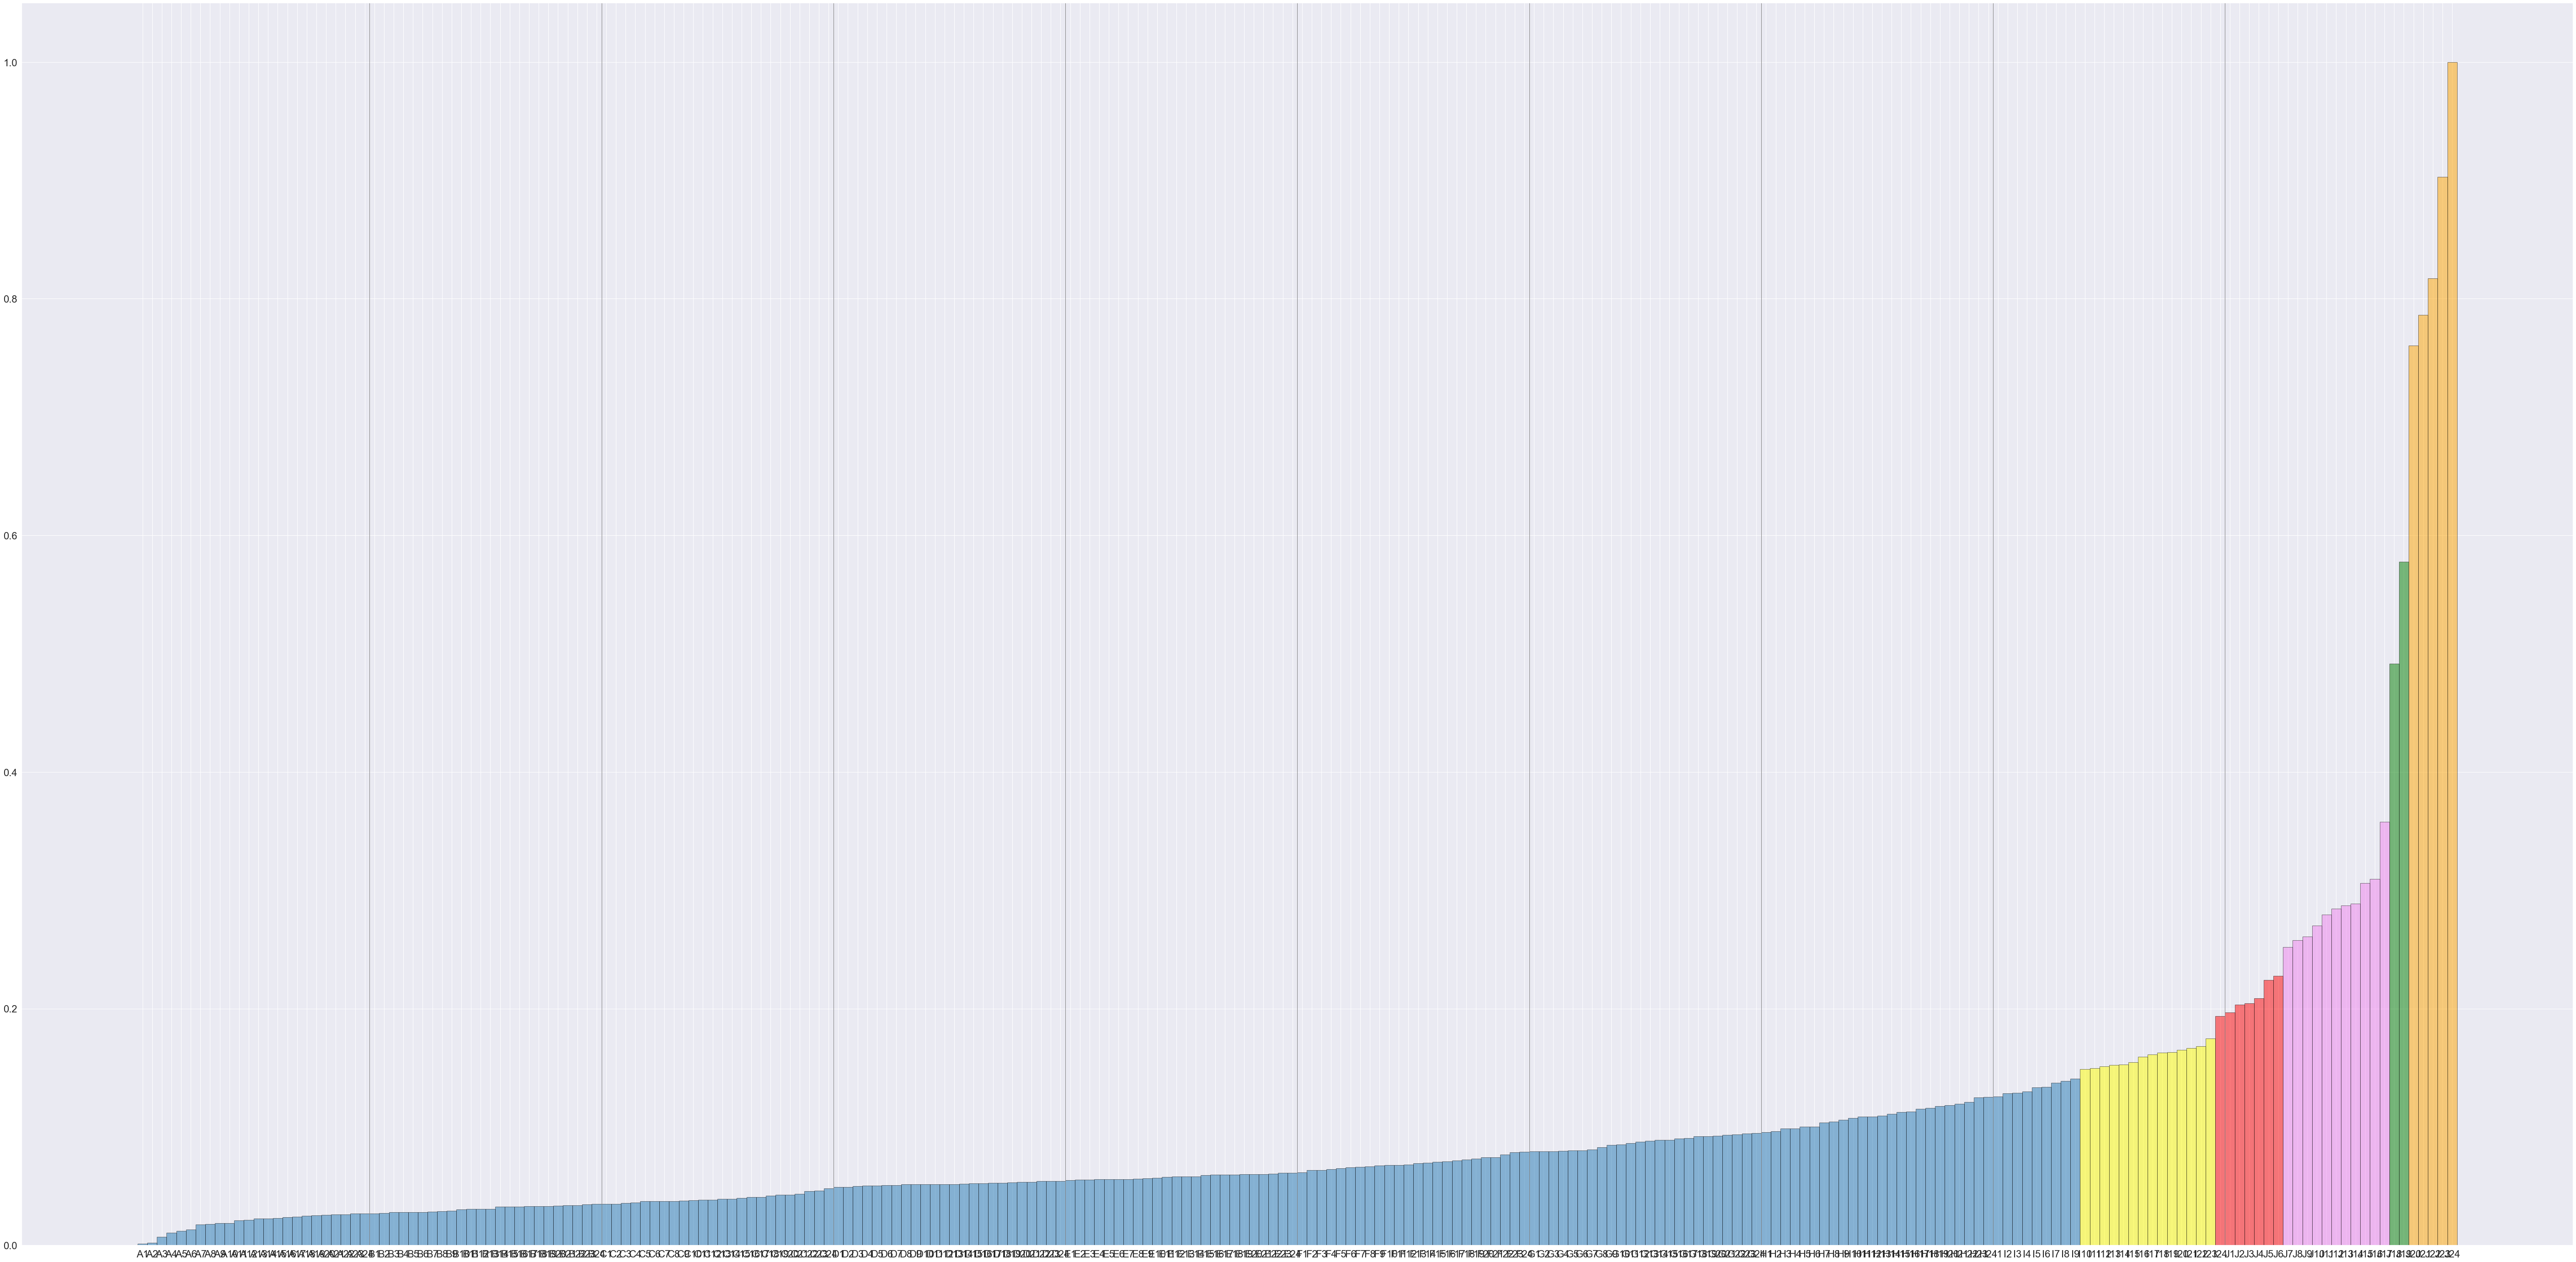

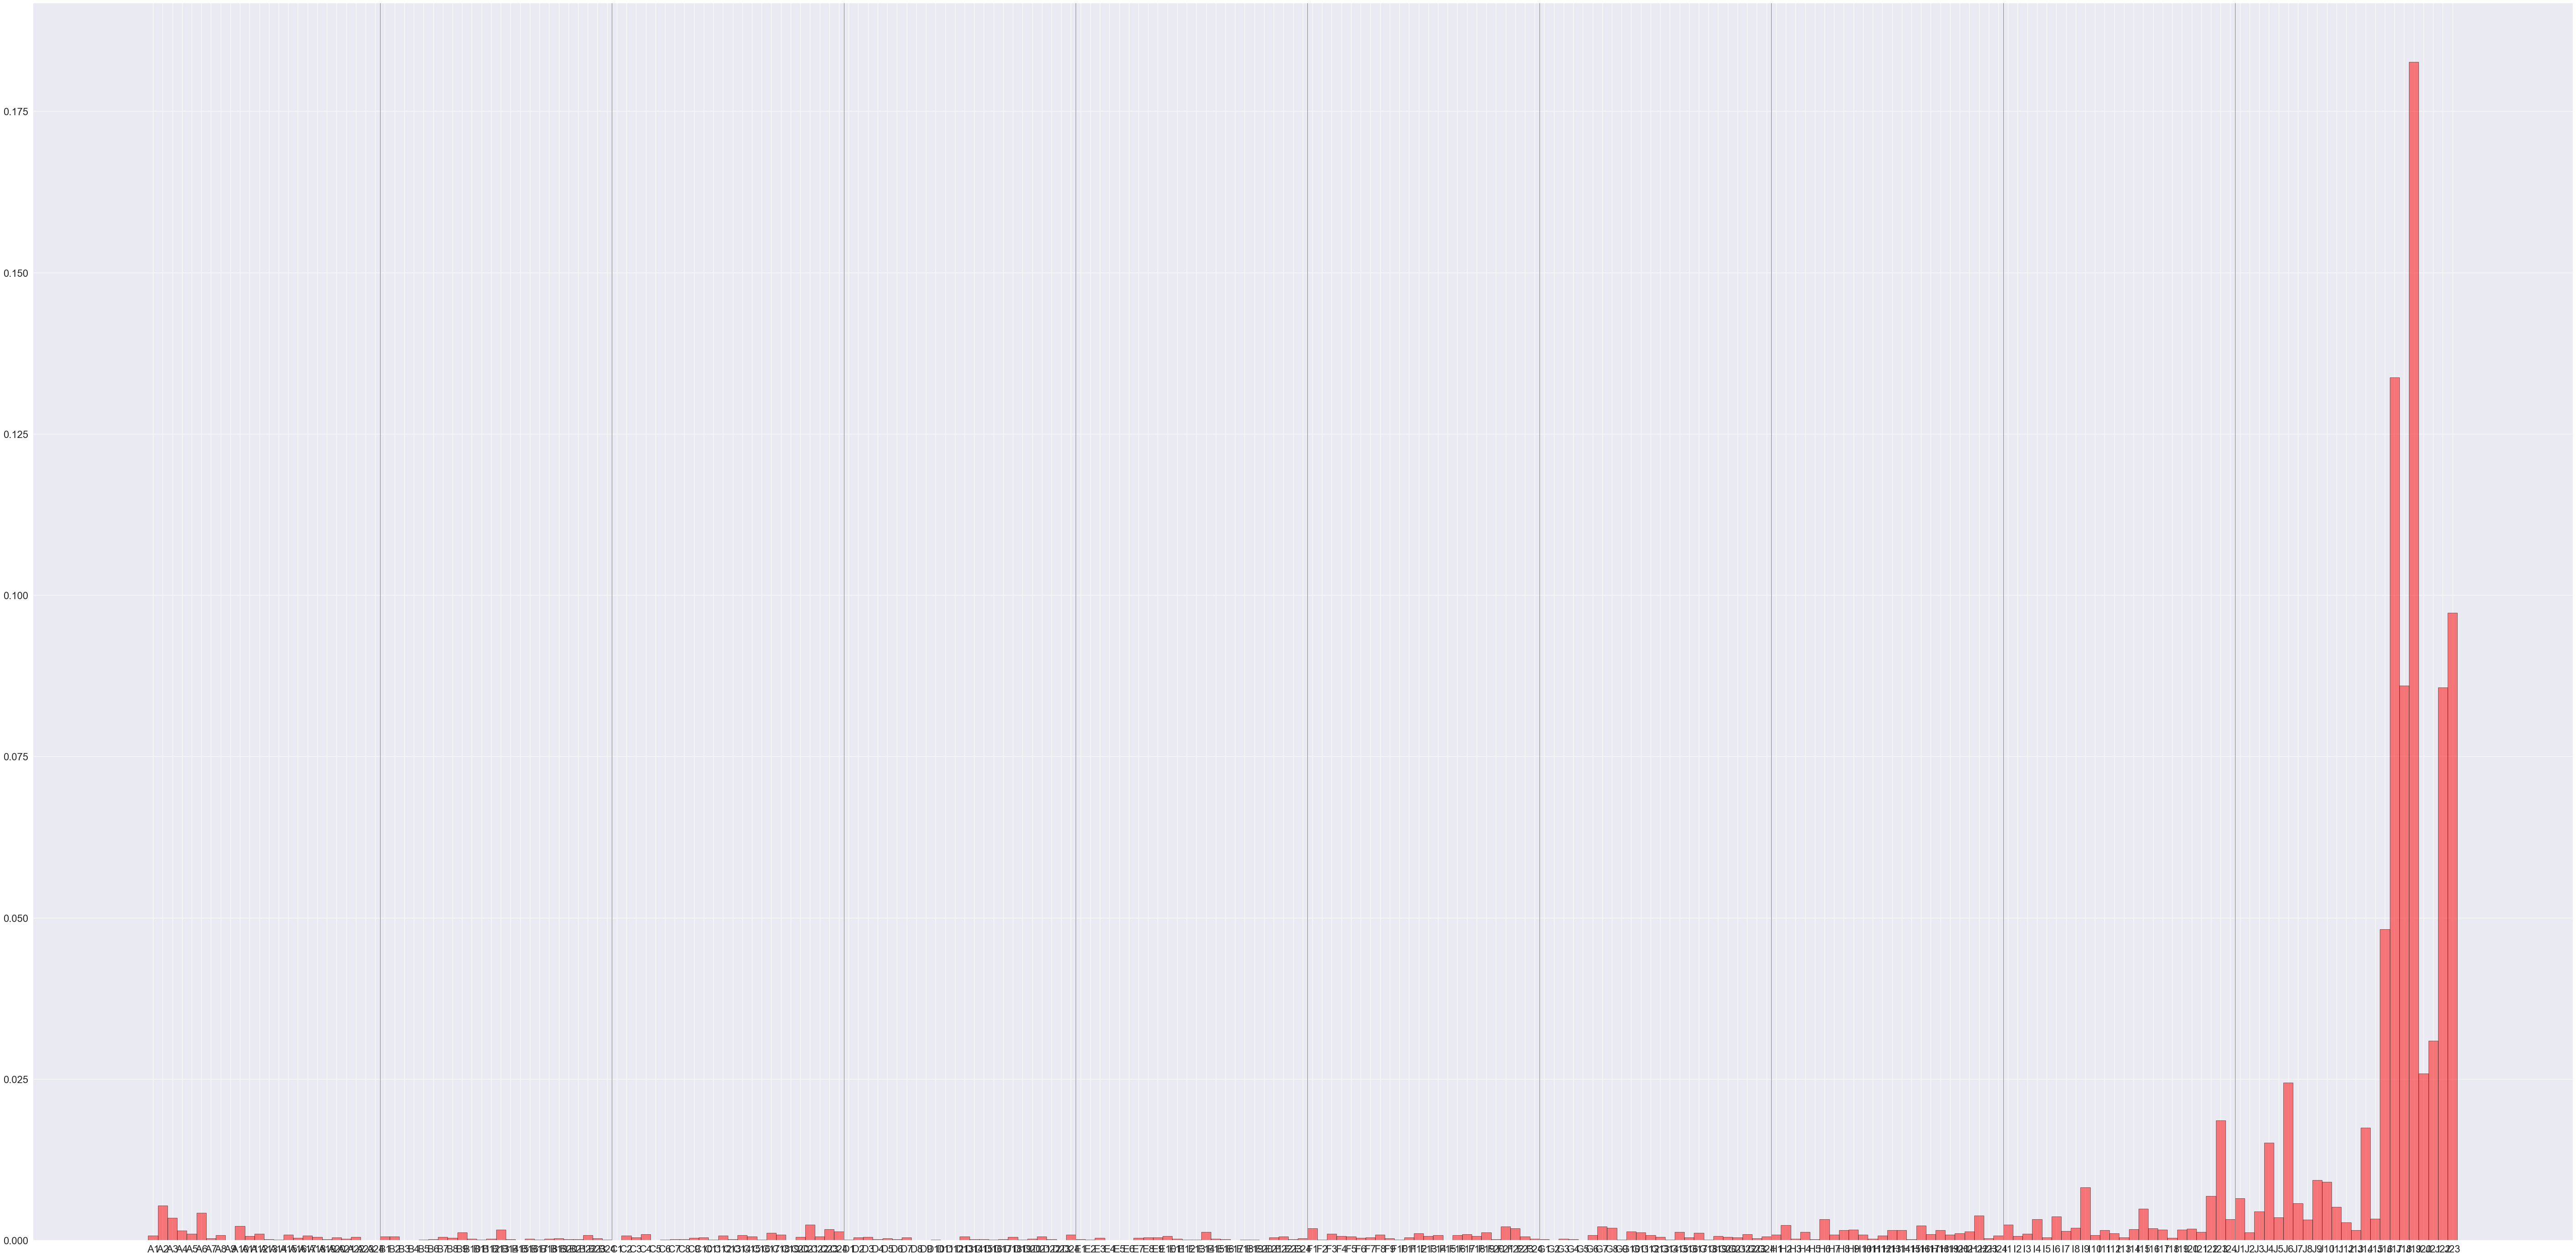

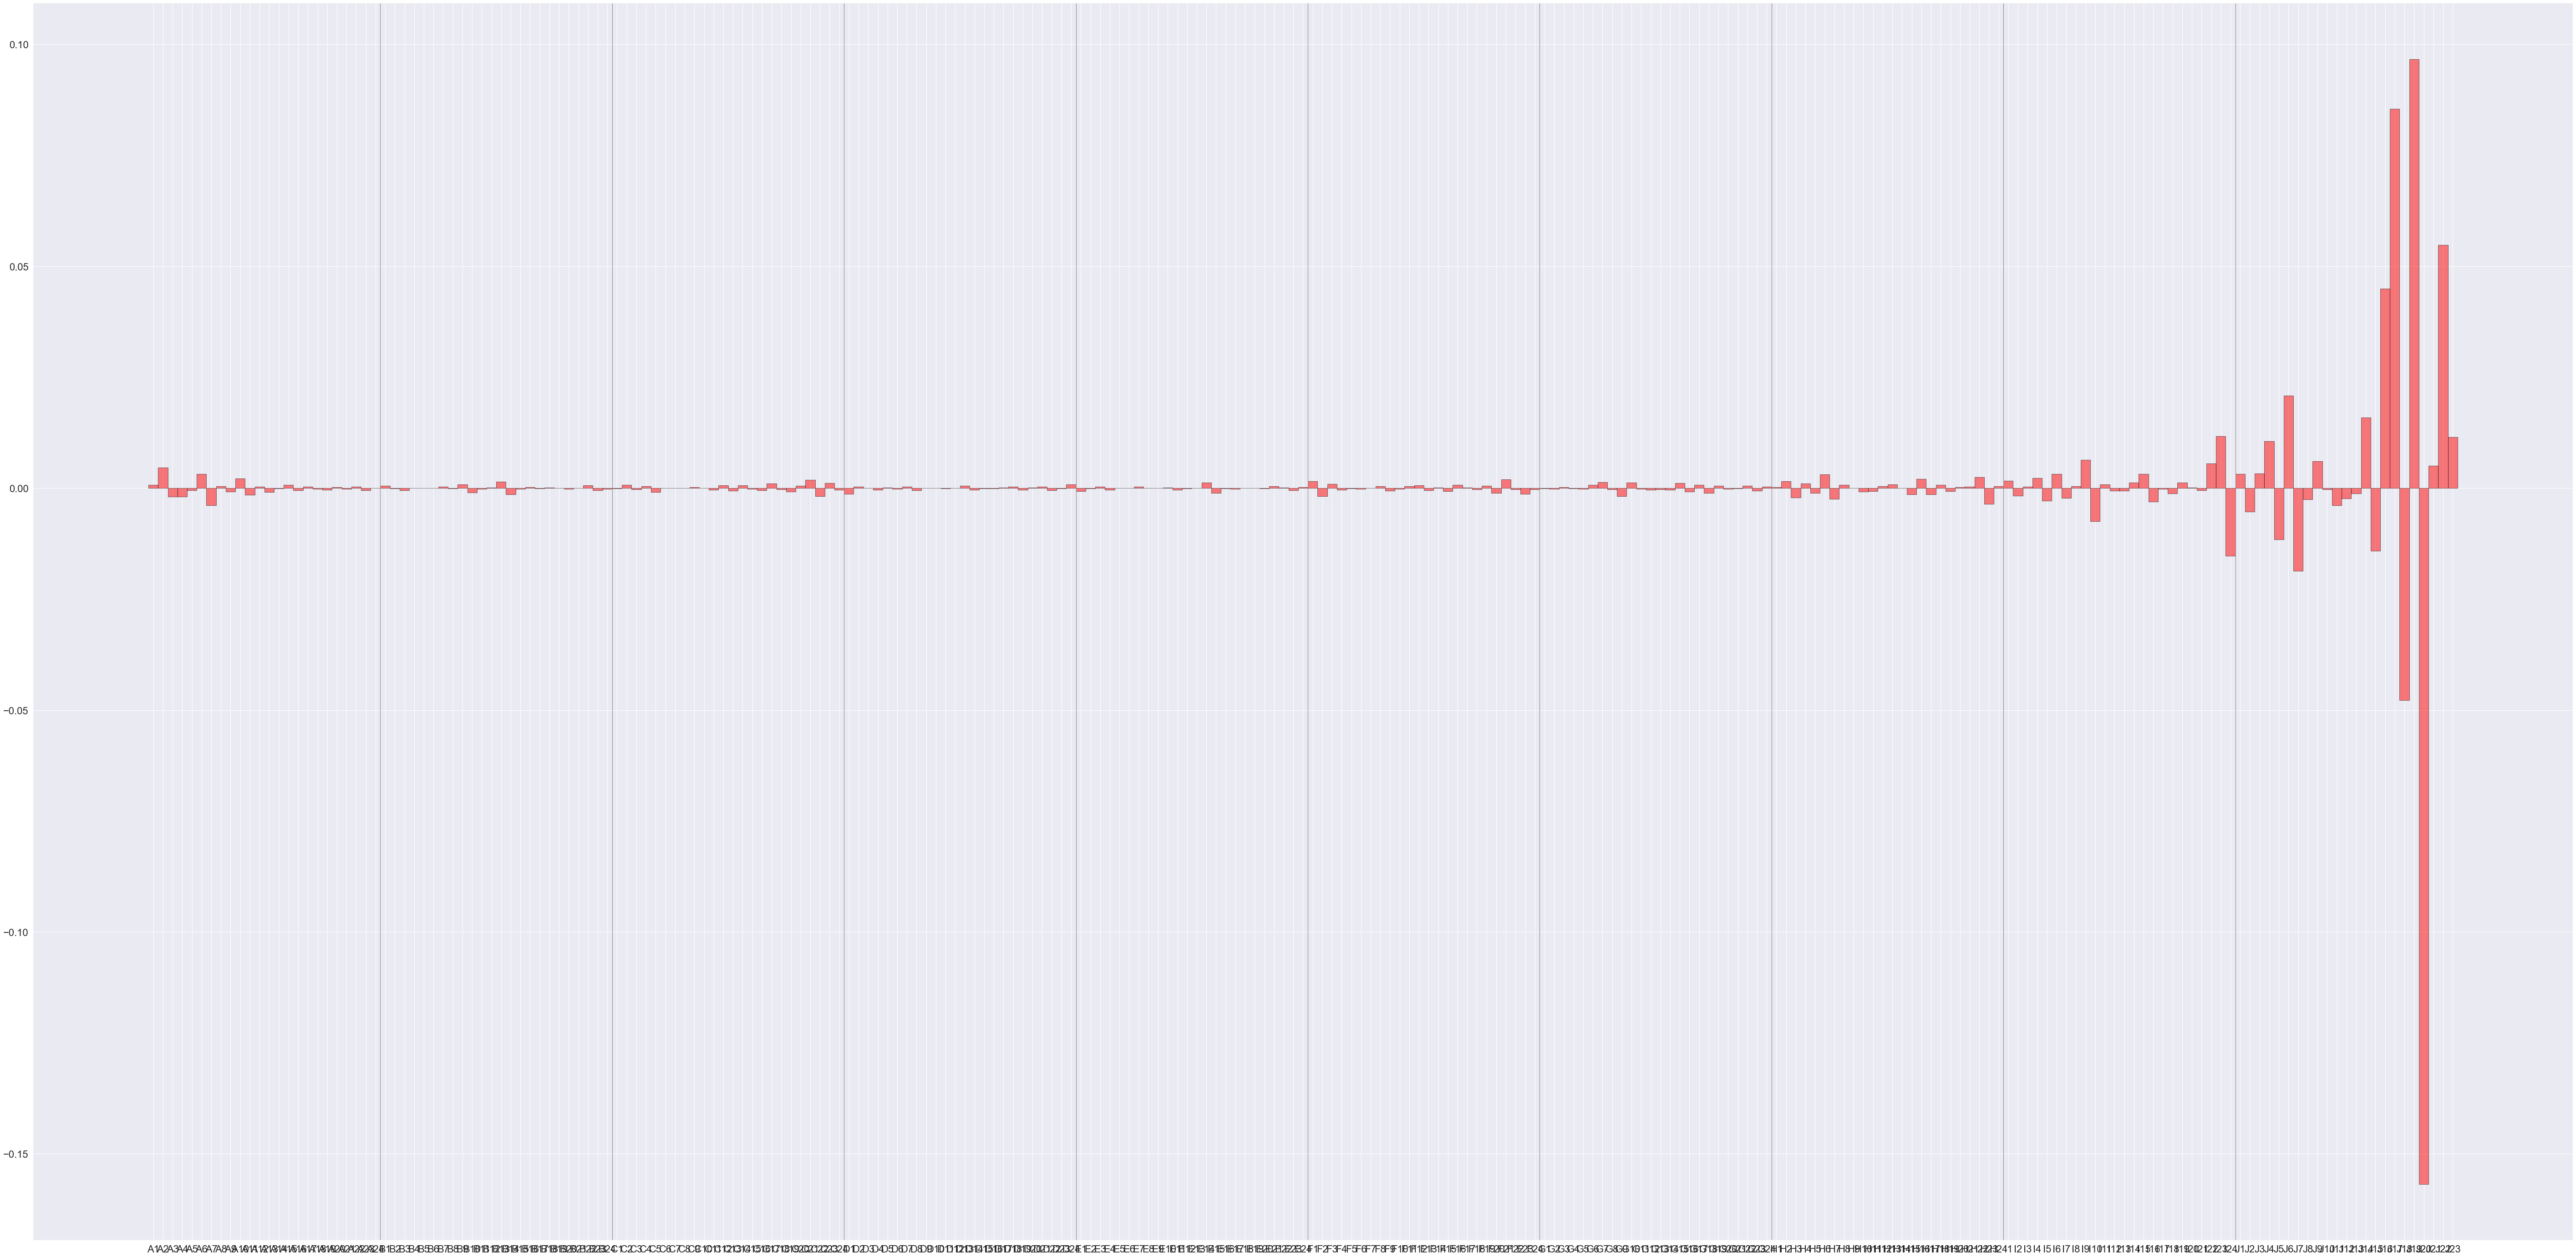

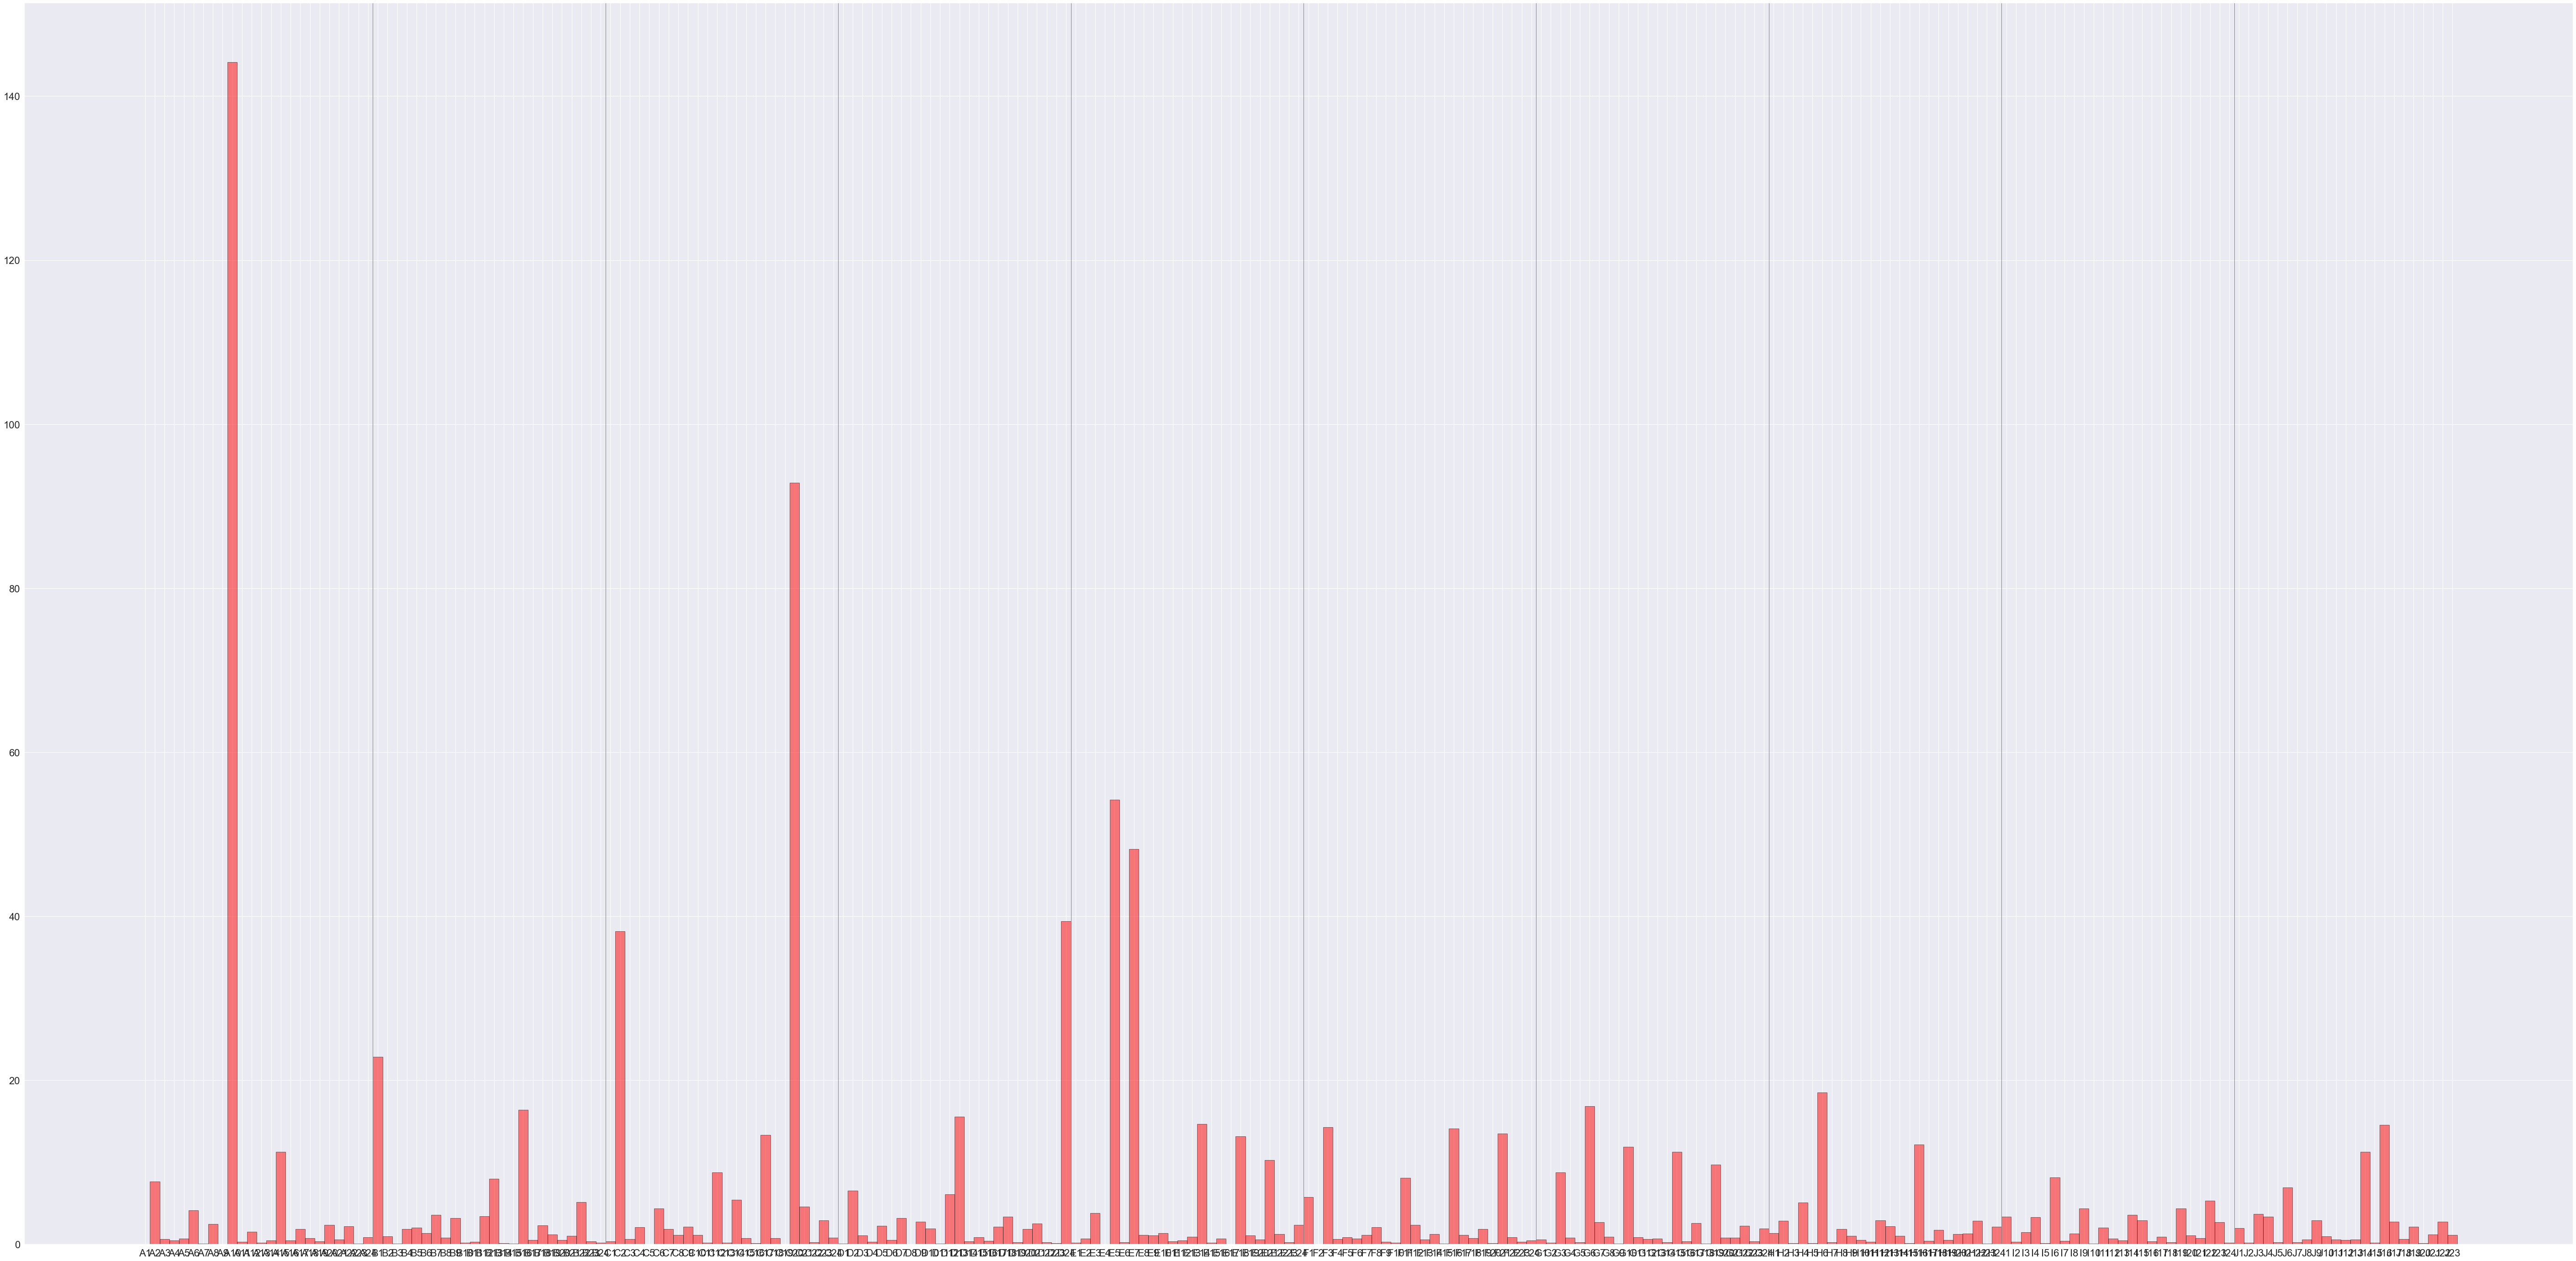

In [35]:
dPath = "C:/Users/KaiKr/Desktop/plots/SYNI.json"
with open(dPath) as file:
        data = json.load(file)


getBarchart(data)
getDeltaBarchart(data)
getDeltaDiffBarchart(data)
#scanFile(data)
#getDeltaSet(data)